# Boréal Marché — Association-rule mining (Apriori)
Offline part of the system: loads 1,000,000 baskets, mines rules with `mlxtend.apriori`, evaluates them, and saves `models/rules.json` + `models/metadata.json` for the Streamlit app.

**Run with Kernel → Restart & Run All.** Total run time is about 5 minutes. The slow default-settings test (Phase 2.1) is switched off by default — see `RUN_DEFAULT_APRIORI`.

In [1]:
# ── Setup: every import and setting used in this notebook ──
# Environment: conda env "boreal" (Python 3.12) — packages in ../requirements.txt
import os, json, time, datetime, platform, tracemalloc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

import mlxtend
from mlxtend.frequent_patterns import apriori, association_rules

# Paths (the notebook lives in notebooks/, so everything is one level up)
DATA_DIR    = '../data'
MODELS_DIR  = '../models'
REPORTS_DIR = '../reports'
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

# Thresholds chosen for the final rule set (justified in Phases 2 and 3)
MIN_SUPPORT    = 0.01
MIN_CONFIDENCE = 0.1
MIN_LIFT       = 1.2

# Phase 2.1 runs Apriori with its DEFAULT settings, which needs 8-70 GB of RAM and can freeze the PC.
# Leave False to show the results already recorded; set True only to re-measure them.
RUN_DEFAULT_APRIORI = False

pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 200)

print('Working directory:', os.getcwd())
print('Data files:', os.listdir(DATA_DIR))
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | mlxtend {mlxtend.__version__}')

Working directory: c:\Users\darth\OneDrive\Documents\GitHub\boreal-reco-knikop\notebooks
Data files: ['products.csv', 'transactionsdata.zip']
Python 3.12.16 | pandas 3.1.0 | numpy 2.5.4 | mlxtend 0.25.0


## Phase 1 - Load and prepare

### 1.1 Load and verify the data

In [2]:
tx = pd.read_csv(f'{DATA_DIR}/transactionsdata.zip', parse_dates=['Date'])
products = pd.read_csv(f'{DATA_DIR}/products.csv')

print(tx['TransactionID'].nunique(), 'baskets')     # expect 1,000,000
print(tx['Item'].nunique(), 'products')              # expect 98
print(len(tx) / tx['TransactionID'].nunique())       # expect 8.38 items per basket
print(tx.duplicated(['TransactionID','Item']).sum()) # expect 0 (no item twice in a basket)
print('Items missing from products.csv:', set(tx['Item']) - set(products['Item']))

1000000 baskets
98 products
8.379837
0
Items missing from products.csv: set()


### 1.2 Build the boolean baskets × products table
Fast method: integer-code baskets and items with `pd.factorize`, then write `True` into a NumPy bool array.

In [3]:
t = time.perf_counter()
row, basket_ids = pd.factorize(tx['TransactionID'])
col, items      = pd.factorize(tx['Item'])
B = np.zeros((len(basket_ids), len(items)), dtype=bool)
B[row, col] = True
basket = pd.DataFrame(B, index=basket_ids, columns=items)
fast_seconds = time.perf_counter() - t
print(f'factorize + NumPy: {fast_seconds:.2f}s, {basket.memory_usage().sum()/1e6:.0f} MB '
      f'(98 MB of bool data + 8 MB int64 TransactionID index)')
print(basket.shape)

factorize + NumPy: 1.04s, 106 MB (98 MB of bool data + 8 MB int64 TransactionID index)
(1000000, 98)


Naive method for comparison (`crosstab` builds an int64 count table first, then converts):

In [4]:
t = time.perf_counter()
naive = pd.crosstab(tx['TransactionID'], tx['Item']).astype(bool)
naive_seconds = time.perf_counter() - t
print(f'crosstab: {naive_seconds:.1f}s  vs  factorize: {fast_seconds:.2f}s')
del naive   # free the memory, we keep the fast version

crosstab: 63.4s  vs  factorize: 1.04s


### 1.3 Product frequencies

In [5]:
freq = basket.mean().sort_values(ascending=False)   # share of baskets containing each item
display(freq.head(10))
display(freq.tail(5))

Sac réutilisable     0.900026
Biscuits             0.161439
Noix mélangées       0.155189
Beurre d'arachide    0.153726
Bière                0.150468
Savon à vaisselle    0.149820
Fromage cheddar      0.143457
Charbon de bois      0.140561
Papier hygiénique    0.139758
Céréales             0.139198
dtype: float64

Safran                         0.000818
Huile de truffe                0.000817
Caviar                         0.000810
Vinaigre balsamique vieilli    0.000779
Foie gras                      0.000756
dtype: float64

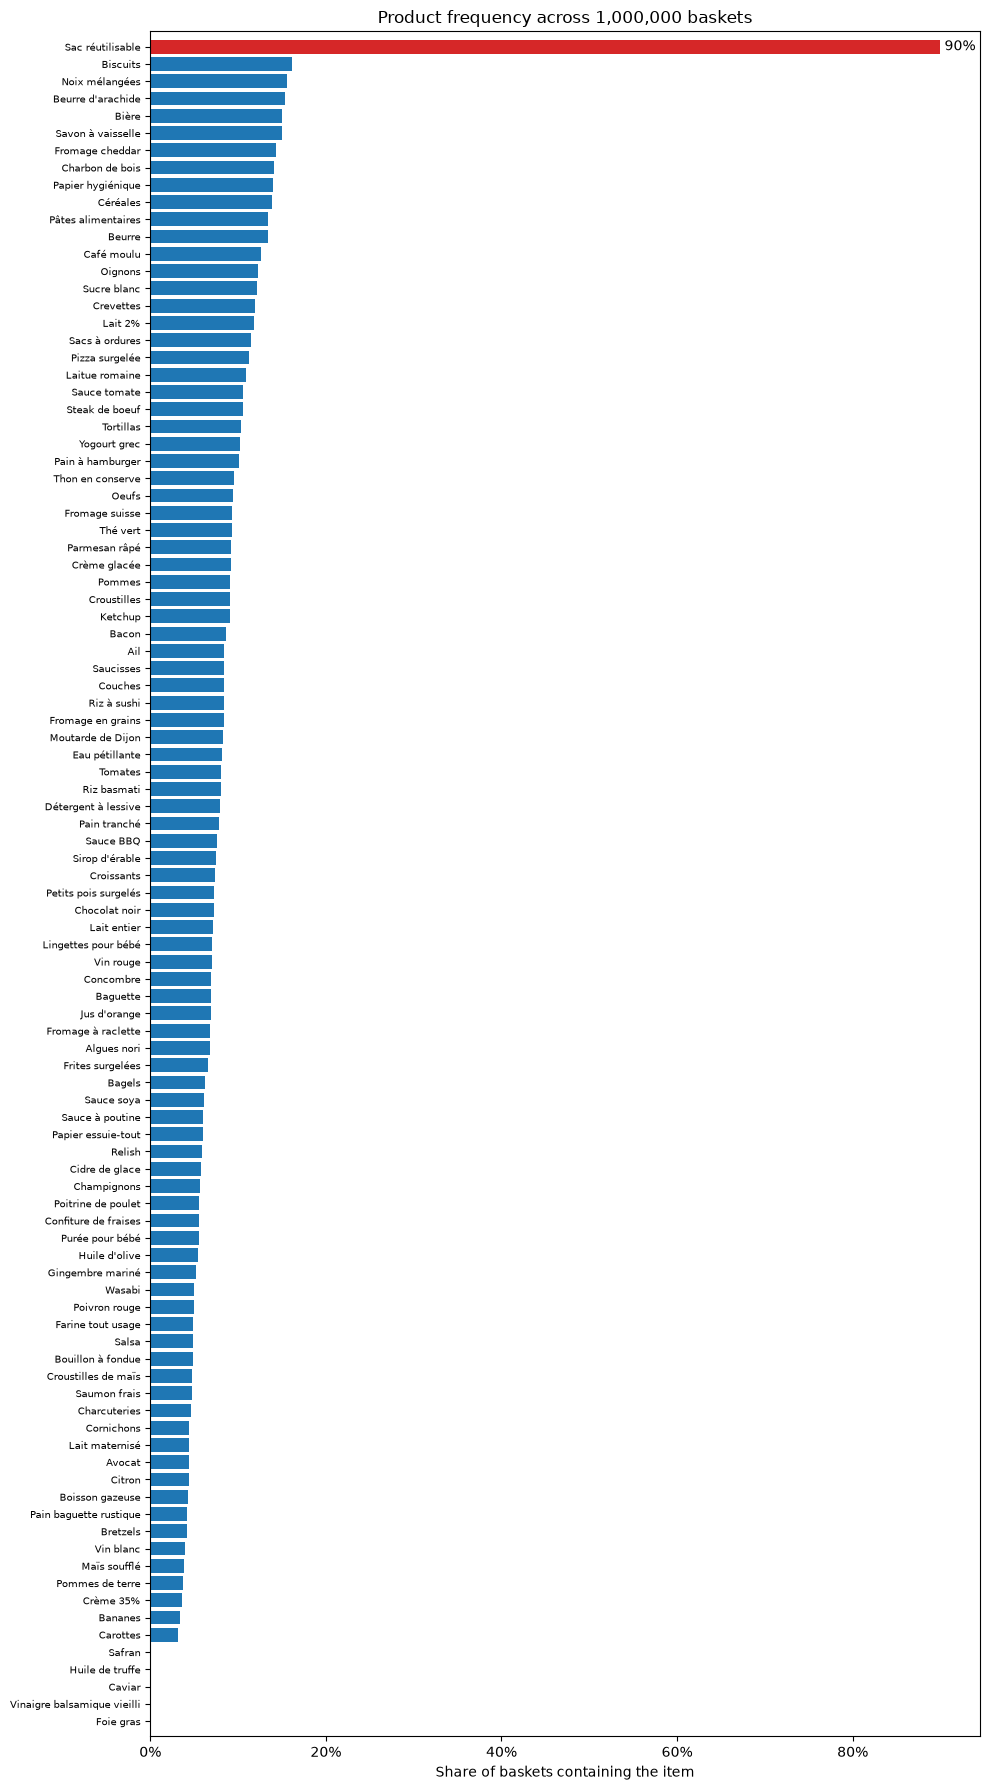

In [6]:
# The 5 specialty items at the bottom are only ~0.08%, so their bars are too small to see:
# evidence that the app will not be able to recommend them.
freq_plot = freq.sort_values()                      # smallest at the bottom of a barh
colors = ['tab:red' if i == 'Sac réutilisable' else 'tab:blue' for i in freq_plot.index]

fig, ax = plt.subplots(figsize=(10, 18))            # tall, so all 98 names are readable
ax.barh(freq_plot.index, freq_plot.values, color=colors)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel('Share of baskets containing the item')
ax.set_title('Product frequency across 1,000,000 baskets')
ax.tick_params(axis='y', labelsize=7)
ax.margins(y=0.005)
ax.text(freq.iloc[0], len(freq) - 1, f' {freq.iloc[0]:.0%}', va='center')
plt.tight_layout()
plt.show()

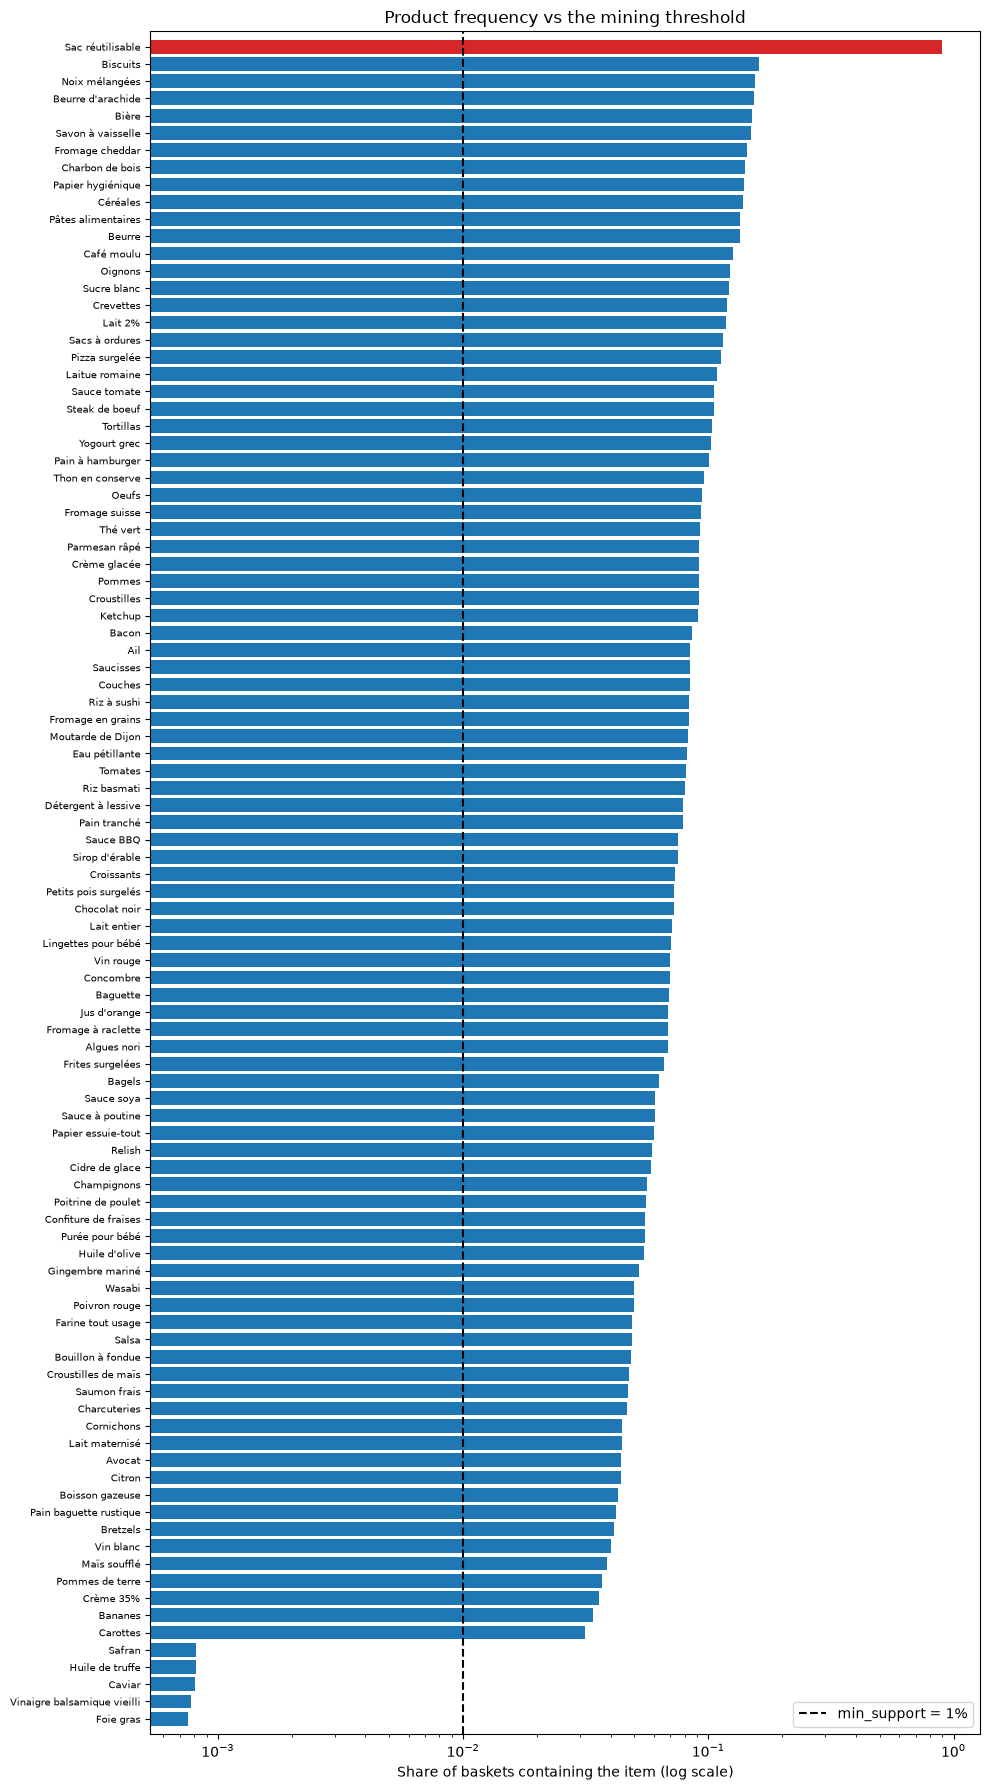

In [7]:
# Same chart on a log scale: the specialty items become visible, and the dashed line is MIN_SUPPORT
fig, ax = plt.subplots(figsize=(10, 18))
ax.barh(freq_plot.index, freq_plot.values, color=colors)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xscale('log')
ax.axvline(MIN_SUPPORT, ls='--', color='black', label=f'min_support = {MIN_SUPPORT:.0%}')
ax.set_xlabel('Share of baskets containing the item (log scale)')
ax.set_title('Product frequency vs the mining threshold')
ax.tick_params(axis='y', labelsize=7)
ax.margins(y=0.005)
ax.legend()
plt.tight_layout()
plt.show()

### 1.4 
Troublemaking product = Sac reutilisable
- When a product appears in 90% of all shopping carts, it naturally triggers a massive amount of high-confidence rules (like 'X → reusable bag'). 
- However, these rules are functionally useless because customers are buying the bag regardless of what else is in their cart.
- Also the 5 specialty products will not be recommended since they will not reach the min_support cutoff.

### 1.5 Duplicate product: Baguette vs Pain baguette rustique

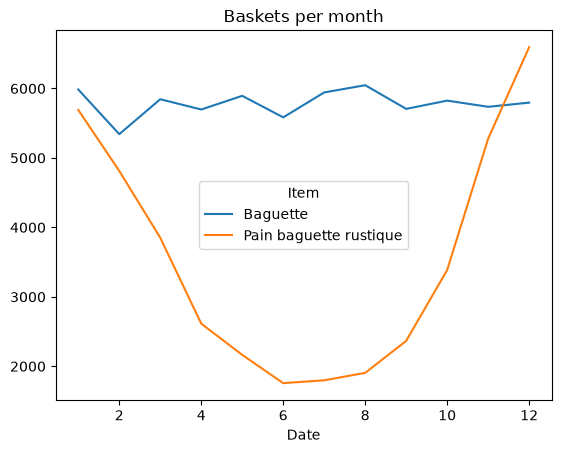

lift(Baguette, Pain baguette rustique) = 1.027
Baguette -> {'Vinaigre balsamique vieilli': 1.15, 'Sauce à poutine': 1.03, 'Foie gras': 1.03, 'Pain baguette rustique': 1.03, 'Salsa': 1.03}
Pain baguette rustique -> {'Fromage à raclette': 9.55, 'Bouillon à fondue': 8.49, 'Charcuteries': 8.38, 'Cornichons': 8.19, 'Vin blanc': 7.79}


In [8]:
monthly = tx.groupby([tx.Date.dt.month, 'Item']).size().unstack()
monthly[['Baguette', 'Pain baguette rustique']].plot(title='Baskets per month')
plt.show()

a, b = basket['Baguette'], basket['Pain baguette rustique']
lift_ab = (a & b).mean() / (a.mean() * b.mean())
print(f'lift(Baguette, Pain baguette rustique) = {lift_ab:.3f}')   # expected ~1.03

# What is each one bought with? (top 5 partners by lift)
co = basket.astype(np.float32).T @ basket.astype(np.float32) / len(basket)
lift_matrix = co / np.outer(freq.reindex(co.index), freq.reindex(co.index))
for item in ['Baguette', 'Pain baguette rustique']:
    print(item, '->', lift_matrix[item].drop(item).sort_values(ascending=False).head(5).round(2).to_dict())

In [9]:
# What merging would do to the raclette signal
merged = basket['Baguette'] | basket['Pain baguette rustique']
rac = basket['Fromage à raclette']
print(f'Merged support: {merged.mean():.3f}')
print(f"Lift with Fromage à raclette — rustic only: {lift_matrix.loc['Pain baguette rustique', 'Fromage à raclette']:.2f}, "
      f"merged: {(merged & rac).mean() / (merged.mean() * rac.mean()):.2f}")

Merged support: 0.109
Lift with Fromage à raclette — rustic only: 9.55, merged: 4.09


**Decision — merge or keep separate?**

**Keep them separate.** Both are baguettes in *Boulangerie*, but the data shows two products with different behaviour. Baguette is flat all year (about 5,300–6,000 baskets a month) and has no strong partner (its best lift is 1.15). Pain baguette rustique is seasonal (about 6,600 baskets in December, 1,800 in June) and belongs to the raclette bundle (lift 9.55 with Fromage à raclette, 8.49 with Bouillon à fondue). The lift between the two is 1.03, so they are bought independently of each other.

Merging would give one simpler "baguette" item with slightly higher support (10.9% of baskets). But it would dilute the raclette signal: the merged item's lift with Fromage à raclette falls from 9.55 to 4.09 (cell above), because everyday baguette purchases would be mixed in. That would weaken one of the strongest winter recommendations, so the cost outweighs the gain.

## Phase 2 - Mine the rules with Apriori

### 2.1 Default settings (`low_memory=False`) — the MemoryError
This cell needs 8 GB (0.02), 14 GB (0.01) and 73 GB (0.005) of RAM. On my machine it took about 10 minutes and froze the PC while Windows swapped memory to disk. The results below were recorded on 2026-11-03; set `RUN_DEFAULT_APRIORI = True` in the setup cell to re-measure.

In [10]:
# Results recorded when this cell was run with RUN_DEFAULT_APRIORI = True (2026-11-03)
RECORDED_DEFAULT_RUNS = [
    dict(min_support=0.05,  outcome='OK: 191 itemsets', seconds=64.4),
    dict(min_support=0.02,  outcome='OK: 658 itemsets', seconds=210.3),
    dict(min_support=0.01,  outcome='MemoryError: Unable to allocate 14.2 GiB for an array with shape (5099, 3, 1000000) and data type bool', seconds=132.7),
    dict(min_support=0.005, outcome='MemoryError: Unable to allocate 72.6 GiB for an array with shape (25975, 3, 1000000) and data type bool', seconds=161.7),
]

if RUN_DEFAULT_APRIORI:
    default_runs = []
    for ms in [0.05, 0.02, 0.01, 0.005]:
        t = time.perf_counter()
        try:
            it = apriori(basket, min_support=ms, use_colnames=True)   # low_memory=False (default)
            outcome = f'OK: {len(it)} itemsets'
            del it
        except MemoryError as e:
            outcome = f'MemoryError: {e}'
        secs = time.perf_counter() - t
        print(f'min_support={ms}: {outcome} ({secs:.1f}s)')
        default_runs.append(dict(min_support=ms, outcome=outcome, seconds=round(secs, 1)))
else:
    default_runs = RECORDED_DEFAULT_RUNS
    print('Showing recorded results (RUN_DEFAULT_APRIORI = False).')

default_df = pd.DataFrame(default_runs)
default_df.to_csv(f'{REPORTS_DIR}/apriori_default_runs.csv', index=False)
display(default_df)

Showing recorded results (RUN_DEFAULT_APRIORI = False).


,min_support,outcome,seconds
0,0.050,OK: 191 itemsets,64.4
1,0.020,OK: 658 itemsets,210.3
2,0.010,"MemoryError: Unable to allocate 14.2 GiB for an array with shape (5099, 3, 1...",132.7
3,0.005,"MemoryError: Unable to allocate 72.6 GiB for an array with shape (25975, 3, ...",161.7


**Why it fails:**
Memory bottlenecks occur because the evaluation array scales cubically across candidate itemsets, items per candidate, and total baskets. For example, at a minimum support of 0.01, tracking 5,099 3-item candidates across 1,000,000 baskets requires a massive 15.3 billion boolean matrix, consuming roughly 14.2 GiB of RAM.
Setting low_memory=False forces mlxtend to instantiate this entire array simultaneously to run fully vectorised comparisons. Because dropping the support threshold triggers combinatorial growth in candidate counts (shifting from 4,278 to 5,099 and jumping to 25,975), the matrix size scales aggressively when multiplied by 1 million transactions. This explosion is heavily driven by nearly universal items like the "Sac réutilisable" (90% support), which pairs with almost every other frequent item and artificially inflates candidate generation at every level.

### 2.2 The fix: `low_memory=True` — benchmark at four thresholds

In [11]:
results = []
for ms in [0.05, 0.02, 0.01, 0.005]:
    tracemalloc.start(); t = time.perf_counter()
    itemsets = apriori(basket, min_support=ms, use_colnames=True, low_memory=True)
    rules = association_rules(itemsets, metric='confidence', min_threshold=MIN_CONFIDENCE)
    elapsed = time.perf_counter() - t
    _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
    results.append(dict(min_support=ms, itemsets=len(itemsets), rules=len(rules),
                        seconds=round(elapsed, 1), peak_GB=round(peak/1e9, 2),
                        longest=itemsets['itemsets'].map(len).max()))
bench = pd.DataFrame(results)
bench.to_csv(f'{REPORTS_DIR}/apriori_lowmem_runs.csv', index=False)
bench

,min_support,itemsets,rules,seconds,peak_GB,longest
0,0.050,191,306,3.5,0.16,4
1,0.020,658,3468,7.7,0.18,5
2,0.010,2267,13731,18.3,0.18,7
3,0.005,7106,41952,38.5,0.18,7


### 2.3 Final mining run at the chosen threshold
The loop above leaves `rules` holding the **last** run (0.005). Re-mine once at `MIN_SUPPORT` so every later phase uses the same rule set.

**Choice: MIN_SUPPORT = 0.01.** It produces 13,731 rules in about 19 s with flat memory (0.18 GB), and itemsets up to 7 items long, so multi-item baskets can trigger multi-item rules. Going to 0.005 triples the rule count (41,952) and doubles the time (39 s) without reaching any new product, because every product except the five specialty items is already above 3% support. Going up to 0.02 cuts the rules to 3,468 and the longest itemset to 5, which loses most of the multi-item patterns.


In [12]:
itemsets = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True, low_memory=True)
rules = association_rules(itemsets, metric='confidence', min_threshold=MIN_CONFIDENCE)
print(f'min_support={MIN_SUPPORT}: {len(itemsets)} itemsets, {len(rules)} rules')   # expect 2267 / 13731

min_support=0.01: 2267 itemsets, 13731 rules


## Phase 3 - Evaluate the rules

### 3.1
Definitions:
- Support: the share of all baskets that contain the whole set of items.
- Confidence: among baskets that contain the left-hand items, the share that also contain the right-hand item.
- Lift: how many times more often the right-hand item is bought with the left-hand items than it would be by chance alone.

### 3.2 Simple rules (one item on each side), ranked two ways

In [13]:
simple = rules[(rules.antecedents.map(len) == 1) & (rules.consequents.map(len) == 1)].copy()
simple['if']   = simple.antecedents.map(lambda s: next(iter(s)))
simple['then'] = simple.consequents.map(lambda s: next(iter(s)))
cols = ['if', 'then', 'support', 'confidence', 'lift']

top_conf = simple.sort_values('confidence', ascending=False)[cols].head(10)
top_lift = simple.sort_values('lift', ascending=False)[cols].head(10)
print('Top 10 by CONFIDENCE'); display(top_conf)
print('Top 10 by LIFT');       display(top_lift)

share_bag = (simple.sort_values('confidence', ascending=False).head(50)['then'] == 'Sac réutilisable').mean()
print(f'Share of the top-50 confidence rules that recommend the bag: {share_bag:.0%}')

Top 10 by CONFIDENCE


,if,then,support,confidence,lift
194,Concombre,Sac réutilisable,0.062853,0.902619,1.002881
0,Cidre de glace,Sac réutilisable,0.052520,0.902034,1.002231
137,Sauce tomate,Sac réutilisable,0.095588,0.901808,1.001980
203,Relish,Sac réutilisable,0.053301,0.901695,1.001854
214,Huile d'olive,Sac réutilisable,0.049201,0.901662,1.001818
171,Pommes,Sac réutilisable,0.082351,0.901617,1.001768
185,Moutarde de Dijon,Sac réutilisable,0.074374,0.901525,1.001665
154,Fromage suisse,Sac réutilisable,0.083997,0.901458,1.001592
184,Steak de boeuf,Sac réutilisable,0.095092,0.901414,1.001543
221,Avocat,Sac réutilisable,0.039907,0.901344,1.001464


Top 10 by LIFT


,if,then,support,confidence,lift
821,Fromage à raclette,Bouillon à fondue,0.033651,0.491198,10.170786
820,Bouillon à fondue,Fromage à raclette,0.033651,0.696780,10.170786
852,Charcuteries,Fromage à raclette,0.031932,0.683403,9.975519
853,Fromage à raclette,Charcuteries,0.031932,0.466106,9.975519
831,Fromage à raclette,Cornichons,0.029733,0.434008,9.772967
830,Cornichons,Fromage à raclette,0.029733,0.669526,9.772967
846,Pain baguette rustique,Fromage à raclette,0.027627,0.654374,9.551784
845,Fromage à raclette,Pain baguette rustique,0.027627,0.403267,9.551784
754,Algues nori,Riz à sushi,0.054431,0.795019,9.504685
755,Riz à sushi,Algues nori,0.054431,0.650738,9.504685


Share of the top-50 confidence rules that recommend the bag: 100%


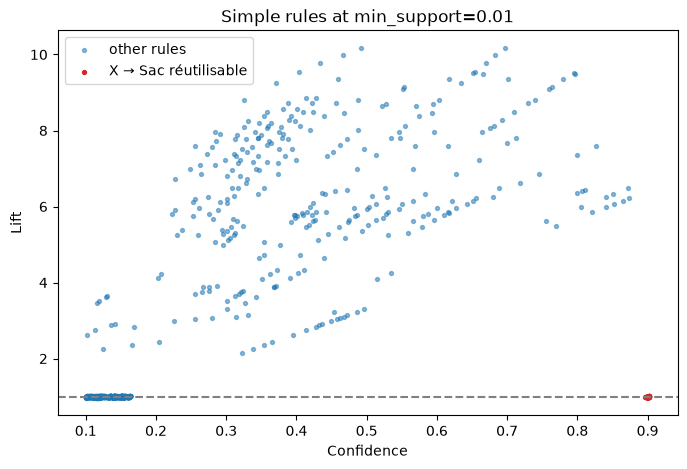

In [14]:
# One picture of the difference: confidence vs lift for every simple rule
is_bag = simple['then'] == 'Sac réutilisable'
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(simple.loc[~is_bag, 'confidence'], simple.loc[~is_bag, 'lift'], s=8, alpha=0.5, label='other rules')
ax.scatter(simple.loc[is_bag, 'confidence'], simple.loc[is_bag, 'lift'], s=8, color='tab:red', label='X → Sac réutilisable')
ax.axhline(1, ls='--', color='grey')
ax.set_xlabel('Confidence'); ax.set_ylabel('Lift')
ax.set_title(f'Simple rules at min_support={MIN_SUPPORT}')
ax.legend()
plt.show()

### 3.3 Comparing the two rankings — was the Phase 1 prediction correct?

**1. What the top-confidence rules have in common.** All ten top rules by confidence end in Sac réutilisable (Concombre → bag, Cidre de glace → bag, Sauce tomate → bag …), and so do 100% of the top 50. Their confidence is about 0.90, but their lift is between 1.001 and 1.003.

**2. Why a high confidence can carry no information.** Confidence only asks how often the right-hand item is in the basket when the left-hand item is. The bag is in 90% of *all* baskets, so it is in about 90% of baskets containing any item. A lift of 1.00 means that knowing the customer bought cucumbers changes nothing about the chance they take a bag. The rule just repeats how popular the bag already is.

**3. What the top-lift rules represent.** The top ten by lift are real meal bundles: raclette night (Fromage à raclette with Bouillon à fondue, Charcuteries, Cornichons, Pain baguette rustique, lift 9.6–10.2) and sushi night (Algues nori ↔ Riz à sushi, lift 9.5). Their confidence is lower (0.40–0.80), but customers buy these items together about 10 times more often than chance. This is the information a recommender needs.

**4. Which ranking to use.** A recommender should rank by lift. A suggestion is only useful if it changes what the customer would have bought. Recommending the bag earns nothing, because 90% of customers take it anyway. Recommending Bouillon à fondue to someone with Fromage à raclette targets a purchase that is 10 times more likely than average. Confidence still matters as a floor (I kept min_confidence = 0.1), but it should not decide the order.

**5. Was the Phase 1 prediction correct?** In 1.4 I wrote: *"When a product appears in 90% of all shopping carts, it naturally triggers a massive amount of high-confidence rules (like 'X → reusable bag'). However, these rules are functionally useless because customers are buying the bag regardless of what else is in their cart."* **The prediction was correct.** The bag takes every top-confidence slot, with lift about 1.00. The second part also held: the five specialty products (0.08% support) appear in no rule at all.

### 3.4 Filtering on lift

In [15]:
# "Bag rules" = rules whose right-hand side is ONLY the bag (X → Sac réutilisable).
# (Testing `'Sac réutilisable' in s` would also catch rules like X → bag + Steak,
#  whose high lift comes from the steak, not the bag.)
BAG = frozenset({'Sac réutilisable'})
is_bag_rule = rules.consequents == BAG

print(f'All rules:              {len(rules)}')
print(f'Rules with lift <= 1:   {(rules.lift <= 1).sum()}')
print(f'Rules X → bag:          {is_bag_rule.sum()}, lift range '
      f'{rules[is_bag_rule].lift.min():.3f} to {rules[is_bag_rule].lift.max():.3f}')
print(f'  ... passing lift > 1:   {(is_bag_rule & (rules.lift > 1)).sum()}')
print(f'  ... passing lift > {MIN_LIFT}: {(is_bag_rule & (rules.lift > MIN_LIFT)).sum()}')
single = rules.consequents.map(len) == 1
print(f'Single-item consequent rules: {single.sum()} | lift > 1: {(single & (rules.lift > 1)).sum()} '
      f'| lift > {MIN_LIFT}: {(single & (rules.lift > MIN_LIFT)).sum()}')

All rules:              13731
Rules with lift <= 1:   1986
Rules X → bag:          1017, lift range 0.992 to 1.009
  ... passing lift > 1:   586
  ... passing lift > 1.2: 0
Single-item consequent rules: 5609 | lift > 1: 4044 | lift > 1.2: 2894


**Justify the filter:**

**Why lift > 1.** Lift above 1 means the items are bought together more often than chance. Lift of 1 means they are independent, and below 1 means customers tend *not* to buy them together. Recommending a rule with lift ≤ 1 is no better than suggesting a random product, so the 1,986 rules with lift ≤ 1 are removed.

**Why lift > 1 was not enough.** The 1,017 rules of the form "X → Sac réutilisable" have lifts between 0.992 and 1.009. That is statistical noise around 1, but 586 of them are just above 1 and survive a lift > 1 filter. The app would then still suggest the bag, the exact problem identified in 3.3.

**Why MIN_LIFT = 1.2.** At 1.2, zero bag rules remain, and 2,894 single-consequent rules are kept. Every genuine pattern in the data has a lift well above 1.2: BBQ rules are around 3.2 and the bundles 6–10. So the cut removes noise without removing real associations. The exact value is a business choice. 1.2 means a suggestion must be at least 20% more likely than chance before the site shows it.

## Phase 4 - Seasonal Analysis

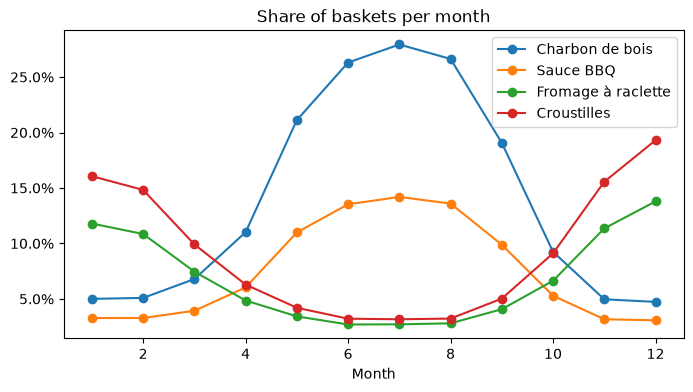

In [16]:
# Month of each basket, aligned on the basket index (= TransactionID)
month = tx.groupby('TransactionID')['Date'].first().dt.month.reindex(basket.index)
assert month.isna().sum() == 0, 'every basket must have a month'

# Monthly share of baskets containing a few seasonal items
share = basket.groupby(month.values)[['Charbon de bois', 'Sauce BBQ', 'Fromage à raclette', 'Croustilles']].mean()
share.plot(marker='o', figsize=(8, 4), title='Share of baskets per month')
plt.gca().yaxis.set_major_formatter(PercentFormatter(1.0))
plt.xlabel('Month'); plt.show()

In [17]:
def mine(b, ms=MIN_SUPPORT):
    it = apriori(b, min_support=ms, use_colnames=True, low_memory=True)
    r  = association_rules(it, metric='confidence', min_threshold=MIN_CONFIDENCE)
    r['rule'] = (r.antecedents.map(lambda s: ' + '.join(sorted(s))) + ' → '
                 + r.consequents.map(lambda s: ' + '.join(sorted(s))))
    return r.set_index('rule')[['support', 'confidence', 'lift']]

summer = basket[month.isin([6, 7, 8]).values]
winter = basket[month.isin([12, 1, 2]).values]
print(f'Summer baskets: {len(summer):,} | Winter baskets: {len(winter):,}')

su, wi = mine(summer), mine(winter)
cmp = su.join(wi, suffixes=('_summer', '_winter'), how='outer')
print(f'Summer rules: {len(su)} | Winter rules: {len(wi)} | in both: {cmp.dropna().shape[0]}')

Summer baskets: 252,474 | Winter baskets: 246,965
Summer rules: 27871 | Winter rules: 9446 | in both: 6413


In [18]:
# The same rules compared across seasons (NaN = the rule does not exist in that season)
watch = ['Charbon de bois → Steak de boeuf', 'Pâtes alimentaires → Sauce tomate',
         'Couches → Lingettes pour bébé', 'Fromage à raclette → Bouillon à fondue',
         'Croustilles → Salsa', 'Saucisses → Sauce BBQ']
display(cmp.reindex(watch).round(3))

,support_summer,confidence_summer,lift_summer,support_winter,confidence_winter,lift_winter
rule,,,,,,
Charbon de bois → Steak de boeuf,0.187,0.695,3.499,0.025,0.509,12.661
Pâtes alimentaires → Sauce tomate,0.088,0.684,6.737,0.086,0.685,6.848
Couches → Lingettes pour bébé,0.053,0.661,9.796,0.052,0.658,9.961
Fromage à raclette → Bouillon à fondue,NaN,NaN,NaN,0.067,0.552,6.808
Croustilles → Salsa,NaN,NaN,NaN,0.070,0.415,5.016
Saucisses → Sauce BBQ,0.070,0.453,3.292,NaN,NaN,NaN


In [19]:
summer_only = cmp[cmp.lift_winter.isna()].sort_values('lift_summer', ascending=False)
winter_only = cmp[cmp.lift_summer.isna()].sort_values('lift_winter', ascending=False)
print(f'{len(summer_only)} rules exist only in summer, {len(winter_only)} only in winter')

# Show the easy-to-read ones: one item on each side (no '+' in the rule)
pair = lambda df: df[~df.index.str.contains(r'\+', regex=True)]
print('Summer only (one item each side):')
display(pair(summer_only)[['support_summer', 'confidence_summer', 'lift_summer']].head(8))
print('Winter only (one item each side):')
display(pair(winter_only)[['support_winter', 'confidence_winter', 'lift_winter']].head(8))

21458 rules exist only in summer, 3033 only in winter
Summer only (one item each side):


,support_summer,confidence_summer,lift_summer
rule,,,
Saucisses → Sauce BBQ,0.070320,0.453498,3.292021
Sauce BBQ → Saucisses,0.070320,0.510466,3.292021
Steak de boeuf → Relish,0.066926,0.336996,3.249297
Relish → Steak de boeuf,0.066926,0.645293,3.249297
Pain à hamburger → Relish,0.063313,0.336031,3.239989
Relish → Pain à hamburger,0.063313,0.610464,3.239989
Relish → Ketchup,0.056061,0.540538,3.209216
Ketchup → Relish,0.056061,0.332840,3.209216


Winter only (one item each side):


,support_winter,confidence_winter,lift_winter
rule,,,
Fromage à raclette → Bouillon à fondue,0.067248,0.551852,6.808285
Bouillon à fondue → Fromage à raclette,0.067248,0.829653,6.808285
Fromage à raclette → Charcuteries,0.064025,0.525403,6.718242
Charcuteries → Fromage à raclette,0.064025,0.818681,6.718242
Fromage à raclette → Cornichons,0.059199,0.485795,6.679343
Cornichons → Fromage à raclette,0.059199,0.813941,6.679343
Pain baguette rustique → Fromage à raclette,0.055162,0.796713,6.537973
Fromage à raclette → Pain baguette rustique,0.055162,0.452667,6.537973


In [20]:
# What happens if the site serves year-round rules in January?
year = mine(basket)
jan  = mine(basket[(month == 1).values])
missing_in_jan = year.index.difference(jan.index)
print(f'{len(missing_in_jan)} of {len(year)} year-round rules do not exist in January data')
display(year.loc[missing_in_jan].sort_values('lift', ascending=False).head(5))

6394 of 13731 year-round rules do not exist in January data


,support,confidence,lift
rule,,,
Riz à sushi + Saumon frais → Sauce soya + Wasabi,0.010926,0.335051,14.229619
Sauce soya + Wasabi → Riz à sushi + Saumon frais,0.010926,0.464028,14.229619
Sauce soya + Saumon frais → Riz à sushi + Wasabi,0.010926,0.501722,14.181751
Riz à sushi + Wasabi → Sauce soya + Saumon frais,0.010926,0.308836,14.181751
Algues nori + Saumon frais → Avocat + Riz à sushi,0.010857,0.422599,14.131395


**Conclusion — how often should Boréal Marché re-mine, and why?**

**The rules are strongly seasonal.** Summer produces 27,871 rules and winter 9,446, and only 6,413 exist in both seasons. 21,458 rules exist only in summer, led by the BBQ bundle (Saucisses → Sauce BBQ, lift 3.29; Relish → Steak de boeuf, 3.25). 3,033 exist only in winter, led by raclette (Fromage à raclette → Bouillon à fondue, lift 6.81) and Croustilles → Salsa (5.02). Some rules are stable all year: Pâtes alimentaires → Sauce tomate (lift 6.7 vs 6.8) and Couches → Lingettes pour bébé (9.8 vs 10.0). Charbon de bois → Steak de boeuf exists in both seasons, but its support collapses from 0.187 to 0.025.

**What a January customer would see with year-round rules.** 6,394 of the 13,731 year-round rules (47%) do not exist in January data. The site would keep pushing patterns that January customers don't follow: summer BBQ pairings such as Saucisses → Sauce BBQ, and multi-item sushi rules that sit right at the 1% threshold. At the same time, the year-round raclette rules understate winter demand: Fromage à raclette → Bouillon à fondue has support 0.034 year-round but 0.067 in winter.

**Re-mining schedule.** Mining the full year at min_support 0.01 takes about 19 seconds, so the cost of re-mining is negligible. I would re-mine **at least monthly** on a recent window of data, and keep a separate rule set per season that the app switches on the date. Mining is cheap and offline, while stale rules cost sales every day they are served.

## Phase 5 — Save the rules (offline → online)
The Streamlit app never runs Apriori: it only loads these two files.

In [21]:
final = rules[(rules.lift > MIN_LIFT) & (rules.consequents.map(len) == 1)]
records = [
    dict(antecedents=sorted(a), consequent=next(iter(c)),
         support=round(float(s), 5), confidence=round(float(cf), 4), lift=round(float(l), 3))
    for a, c, s, cf, l in zip(final.antecedents, final.consequents,
                               final.support, final.confidence, final.lift)
]
with open(f'{MODELS_DIR}/rules.json', 'w', encoding='utf-8') as fh:
    json.dump(records, fh, ensure_ascii=False)

covered = sorted({r['consequent'] for r in records})
meta = dict(
    algorithm='mlxtend.frequent_patterns.apriori (low_memory=True)',
    mlxtend_version=mlxtend.__version__,
    min_support=MIN_SUPPORT, min_confidence=MIN_CONFIDENCE, min_lift=MIN_LIFT,
    rule_filter='lift > min_lift, single-item consequent',
    mined_on=datetime.date.today().isoformat(),
    data_period=f'{tx.Date.min().date()} to {tx.Date.max().date()}',
    n_baskets=len(basket), n_products=basket.shape[1],
    n_rules=len(records),
    coverage=len(covered),
    coverage_share=round(len(covered) / basket.shape[1], 3),
    item_support=freq.round(6).to_dict(),
)
with open(f'{MODELS_DIR}/metadata.json', 'w', encoding='utf-8') as fh:
    json.dump(meta, fh, ensure_ascii=False, indent=2)

print(f'Saved {len(records)} rules; coverage {len(covered)}/{basket.shape[1]} products')
print('rules.json size:', round(os.path.getsize(f"{MODELS_DIR}/rules.json") / 1e6, 2), 'MB')

Saved 2894 rules; coverage 57/98 products
rules.json size: 0.43 MB


## Phase 6 — Coverage and limitations

In [22]:
never = sorted(set(basket.columns) - set(covered))
cov_lift1 = len({next(iter(c)) for c in rules[(rules.lift > 1) & (rules.consequents.map(len) == 1)].consequents})
print(f'Coverage with lift > 1:   {cov_lift1}/98')
print(f'Coverage with lift > {MIN_LIFT}: {len(covered)}/98')
print(f'{len(never)} products can never be recommended:')
print(pd.Series(freq.reindex(never)).sort_values().round(4).to_string())

Coverage with lift > 1:   74/98
Coverage with lift > 1.2: 57/98
41 products can never be recommended:
Foie gras                      0.0008
Vinaigre balsamique vieilli    0.0008
Caviar                         0.0008
Huile de truffe                0.0008
Safran                         0.0008
Carottes                       0.0314
Confiture de fraises           0.0554
Poitrine de poulet             0.0559
Cidre de glace                 0.0582
Papier essuie-tout             0.0600
Bagels                         0.0627
Baguette                       0.0694
Chocolat noir                  0.0727
Petits pois surgelés           0.0728
Pain tranché                   0.0788
Détergent à lessive            0.0792
Riz basmati                    0.0803
Eau pétillante                 0.0820
Moutarde de Dijon              0.0825
Pommes                         0.0913
Crème glacée                   0.0918
Thé vert                       0.0929
Fromage suisse                 0.0932
Thon en conserve        

In [23]:
# The famous 'diapers and beer' rule (for the README's correlation-vs-causation section)
display(simple[(simple['if'].isin(['Couches', 'Bière'])) & (simple['then'].isin(['Couches', 'Bière']))][cols])

,if,then,support,confidence,lift
8,Couches,Bière,0.030696,0.365577,2.429597
9,Bière,Couches,0.030696,0.204004,2.429597


### Two things this approach cannot do, and how to fix each one

**1. It can never recommend 41 of the 98 products.** Coverage is 57/98 with lift > 1.2. The five specialty products (Caviar, Foie gras, Safran, Huile de truffe, Vinaigre balsamique vieilli) are in only 0.08% of baskets, far below the 1% threshold, so they appear in no rule. Lowering min_support to reach them would mean going below 0.0008, where the rule count explodes. Everyday staples (Lait 2%, Fromage cheddar, Papier hygiénique, Savon à vaisselle) are also never suggested, because they are bought with everything and form no strong pattern. This reinforces popularity bias: the catalogue the site promotes is locked to what is already bought together.
*Fix:* compute item-to-item lift directly from the co-occurrence matrix (as in 1.5) for rare items, or use a lower min_support per category, plus a content-based fallback that suggests items from the same category.

**2. It ignores time and season.** One rule set is mined over the whole year, but 6,394 of the 13,731 year-round rules (47%) don't exist in January data, and 21,458 rules exist only in summer. A single rules.json would push BBQ items in winter and understate how common the raclette bundle is in December.
*Fix:* mine one rule set per season (or per month) and have the app load the one matching the current date. Re-mining is cheap (about 19 s at min_support 0.01), so it can run on a monthly schedule.